In [1]:
import pandas as pd

df = pd.read_csv("spam.csv", encoding="latin-1")

print(df.shape)
df.head()

(5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [2]:
df = df[["v1", "v2"]].copy()
df.columns = ["label", "message"]

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after:", df.duplicated().sum())
print("Final dataset shape:", df.shape)

Duplicates before: 403
Duplicates after: 0
Final dataset shape: (5169, 2)


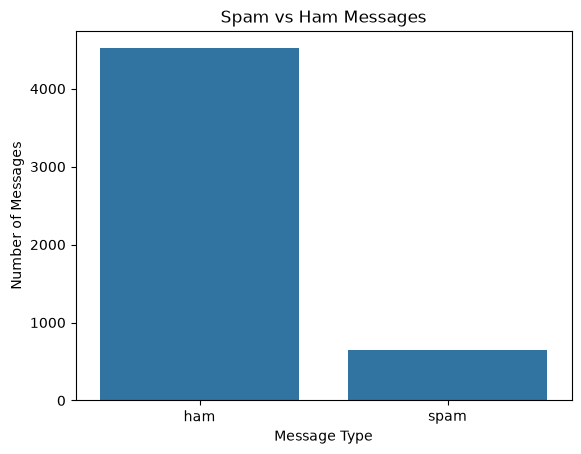

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")
plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4135, 7591)
Testing data shape: (1034, 7591)


In [8]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
y_pred = model.predict(X_test_tfidf)

print("Actual labels:")
print(y_test.head(10).tolist())

print("\nPredicted labels:")
print(y_pred[:10])

Actual labels:
['ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham', 'ham']

Predicted labels:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


Accuracy: 0.9516441005802708

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.62      0.76       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.95      0.95      0.95      1034



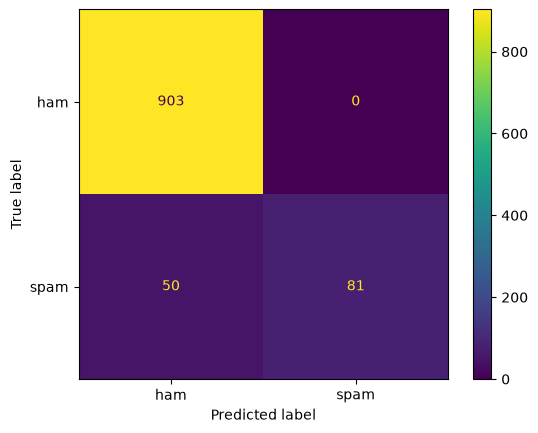

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.show()

In [11]:
message = [
    "Congratulations! You won a free prize. Click here to claim now!"
]

message_tfidf = tfidf.transform(message)

prediction = model.predict(message_tfidf)[0]

print("Prediction:", prediction.upper())

Prediction: SPAM


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
import joblib

spam_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

spam_model.fit(X_train, y_train)

joblib.dump(spam_model, "spam_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [13]:
import os

print(os.path.exists("spam_model.pkl"))
print(os.path.abspath("spam_model.pkl"))

True
C:\Users\DELL\machince learning\spam_model.pkl


In [14]:
import joblib

loaded_model = joblib.load("spam_model.pkl")

message = ["Congratulations! You won a free prize. Claim now!"]

prediction = loaded_model.predict(message)[0]

print("Prediction:", prediction.upper())

Prediction: SPAM


In [20]:
%pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [23]:
import streamlit as st

print(st.__version__)
print("Streamlit installed successfully!")

1.65.0
Streamlit installed successfully!
